# Seaborn for Exploratory Visualization

Use statistical plots to compare distributions, categories, and relationships.

> 🧭 This notebook focuses on practical data work. Examples are intentionally compact and do not cover machine learning.

## Learning goals
- Use `histplot`, `boxplot`, `violinplot`, `scatterplot`, and `heatmap`.
- Map categories to `hue` without overloading a chart.
- Understand that smooth density estimates depend on choices such as bandwidth.
- Keep figure labels and units explicit.

In [1]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

rng = np.random.default_rng(12)
df = pd.DataFrame({
    "group": rng.choice(["A", "B", "C"], 180),
    "value": np.concatenate([rng.normal(10, 2, 60), rng.normal(12, 3, 60), rng.normal(9, 1.5, 60)]),
    "cost": rng.gamma(3, 4, 180),
})
sns.set_theme(style="whitegrid")
display(df.head())

,group,value,cost
0,B,12.346123,6.359948
1,A,9.122336,5.764723
2,C,9.535151,5.575833
3,C,10.547637,7.725777
4,A,11.499270,8.642854


/mnt/data/data_science_data_work/7. Data Visualization/18_seaborn_for_exploratory_analysis.ipynb:7: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  "source": [


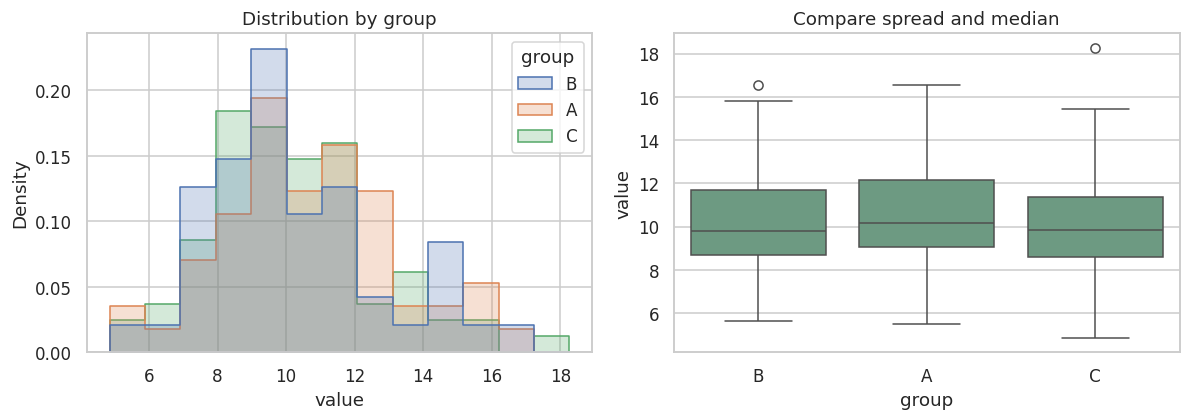

In [2]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
sns.histplot(data=df, x="value", hue="group", element="step", stat="density", common_norm=False, ax=axes[0])
axes[0].set_title("Distribution by group")
sns.boxplot(data=df, x="group", y="value", color="#66A182", ax=axes[1])
axes[1].set_title("Compare spread and median")
plt.tight_layout()
plt.show()

## Relationships and categorical comparisons
`hue` adds a group dimension. Too many categories can make colors unreadable; choose a simpler question or use facets when necessary.

/mnt/data/data_science_data_work/7. Data Visualization/18_seaborn_for_exploratory_analysis.ipynb:7: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  "source": [


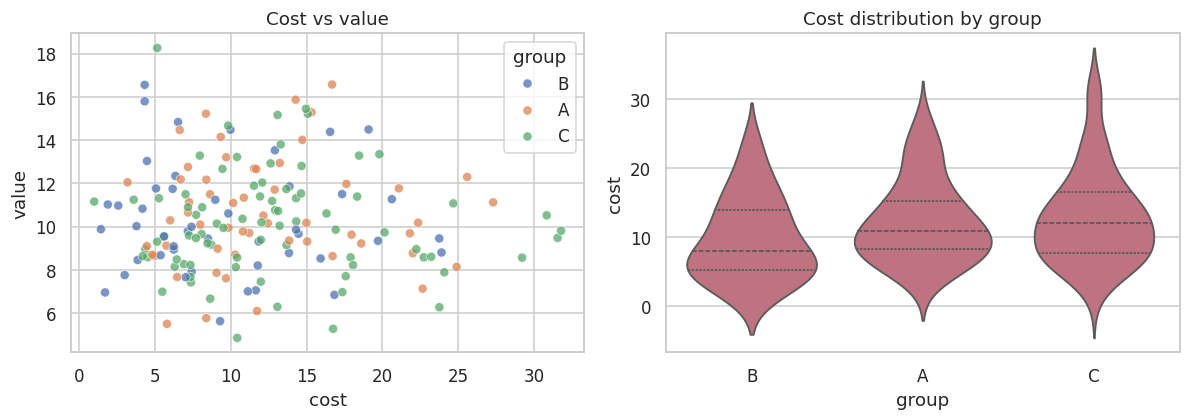

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
sns.scatterplot(data=df, x="cost", y="value", hue="group", alpha=.75, ax=axes[0])
axes[0].set_title("Cost vs value")
sns.violinplot(data=df, x="group", y="cost", inner="quartile", color="#CC6677", ax=axes[1])
axes[1].set_title("Cost distribution by group")
plt.tight_layout()
plt.show()

## Heatmaps and plot interpretation
Heatmaps help identify broad patterns in correlation or cross-tabulated percentages. Correlation heatmaps can be misleading for tiny samples, mixed populations, or variables with nonlinear relationships.

/mnt/data/data_science_data_work/7. Data Visualization/18_seaborn_for_exploratory_analysis.ipynb:4: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  "cell_type": "markdown",
/mnt/data/data_science_data_work/7. Data Visualization/18_seaborn_for_exploratory_analysis.ipynb:9: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  "\n",


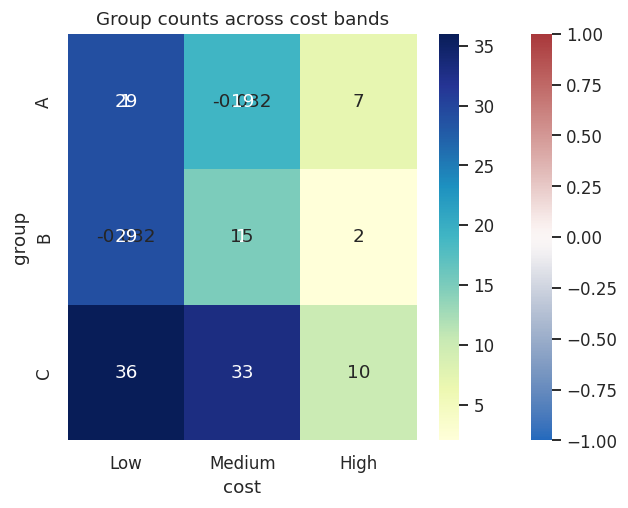

In [4]:
numeric_corr = df[["value", "cost"]].corr()
sns.heatmap(numeric_corr, annot=True, vmin=-1, vmax=1, center=0, cmap="vlag")
plt.title("Correlation heatmap")
plt.show()

counts = pd.crosstab(df["group"], pd.cut(df["cost"], bins=3, labels=["Low", "Medium", "High"]))
sns.heatmap(counts, annot=True, fmt="d", cmap="YlGnBu")
plt.title("Group counts across cost bands")
plt.show()

## Practice
Plot the distribution of a numeric variable by category and use a heatmap to display a crosstab. Add one sentence describing what the plot does and does not prove.

/mnt/data/data_science_data_work/7. Data Visualization/18_seaborn_for_exploratory_analysis.ipynb:3: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  {


cost,"(0.98, 11.263]","(11.263, 21.514]","(21.514, 31.766]"
group,,,
A,29,19,7
B,29,15,2
C,36,33,10


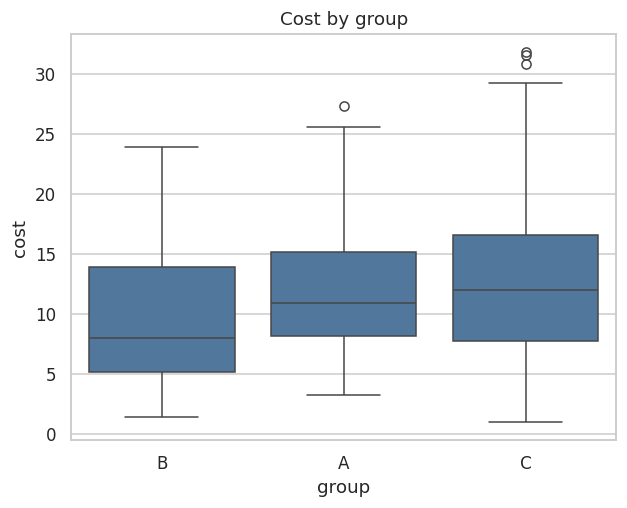

In [5]:
sns.boxplot(data=df, x="group", y="cost", color="#4477AA")
plt.title("Cost by group")
plt.show()
display(pd.crosstab(df["group"], pd.cut(df["cost"], bins=3)))